In [15]:
import numpy as np

pcd_np = np.loadtxt('bike_florent.txt', delimiter=';', skiprows=1)
pcd_np[:5]

array([[  1.17148709,   1.24782467,   2.320436  , 205.        ,
        201.        , 190.        ],
       [  1.45999289,   1.34168911,   2.30516148, 197.        ,
        197.        , 189.        ],
       [  1.32919371,   1.29969215,   2.29750204, 162.        ,
        161.        , 157.        ],
       [  1.51531589,   1.356915  ,   2.30085373, 198.        ,
        199.        , 193.        ],
       [  1.35053456,   1.29682446,   2.29206324, 122.        ,
        121.        , 115.        ]])

In [16]:
print(pcd_np[0])

[  1.17148709   1.24782467   2.320436   205.         201.
 190.        ]


In [17]:
print(pcd_np[:, :3])

[[1.17148709 1.24782467 2.320436  ]
 [1.45999289 1.34168911 2.30516148]
 [1.32919371 1.29969215 2.29750204]
 ...
 [2.58916903 1.47514415 0.39343202]
 [2.6242075  1.52383852 0.39060414]
 [2.76442361 1.74942136 0.35215938]]


In [18]:
print(pcd_np.shape)

(376018, 6)


In [19]:
import pandas as pd

pcd_pd = pd.read_csv('bike_florent.txt', delimiter=';')
pcd_pd.iloc[:5]

,X,Y,Z,R,G,B
0,1.171487,1.247825,2.320436,205,201,190
1,1.459993,1.341689,2.305161,197,197,189
2,1.329194,1.299692,2.297502,162,161,157
3,1.515316,1.356915,2.300854,198,199,193
4,1.350535,1.296824,2.292063,122,121,115


In [20]:
import open3d as o3d

pcd_o3d = o3d.io.read_point_cloud('seychelles-beach.ply')
o3d.visualization.draw_geometries([pcd_o3d])

In [21]:
pcd_np_o3d = o3d.geometry.PointCloud()

pcd_np_o3d.points = o3d.utility.Vector3dVector(pcd_np[:, :3])
pcd_np_o3d.colors = o3d.utility.Vector3dVector(pcd_np[:, 3:] / 255)

o3d.visualization.draw_geometries([pcd_np_o3d])

In [22]:
import laspy as lp

las = lp.read('34FN2_18.las')

points = np.stack([las.x, las.y, las.z]).T
colors = np.stack([las.red, las.green, las.blue]).T / 255**2

pcd_las_o3d = o3d.geometry.PointCloud()
pcd_las_o3d.points = o3d.utility.Vector3dVector(points)
pcd_las_o3d.colors = o3d.utility.Vector3dVector(colors)

o3d.visualization.draw_geometries([pcd_las_o3d])

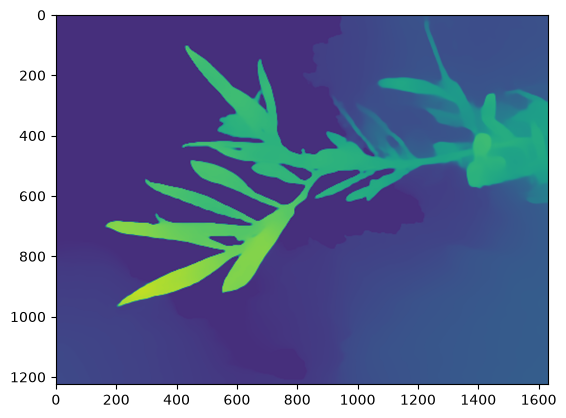

In [23]:
import matplotlib.pyplot as plt

depth_raw = o3d.io.read_image('depth.png')
plt.imshow(depth_raw)
plt.show()

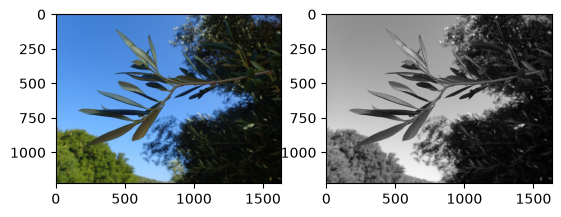

In [24]:
from PIL import Image

plt.subplot(1, 2, 1)
rgb_raw = o3d.io.read_image('rgb.jpg')
rgb_gray = Image.open('rgb.jpg').convert("L")
plt.imshow(rgb_raw)
plt.subplot(1, 2, 2)
plt.imshow(rgb_gray, cmap='gray')
plt.show()

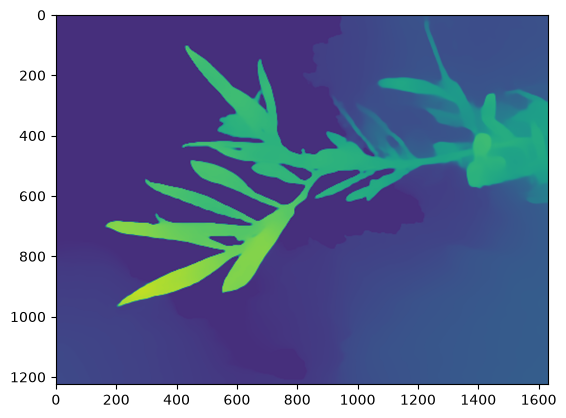

In [25]:
depth_8 = (np.array(depth_raw)/256).astype('uint8')
depth_raw_8 = o3d.geometry.Image((depth_8).astype(np.uint8))
rgbd_image = o3d.geometry.RGBDImage.create_from_color_and_depth(rgb_raw,
depth_raw_8)
plt.imshow(rgbd_image.depth)

In [26]:
vox_read = o3d.io.read_voxel_grid('voxels.ply', format='auto')
o3d.visualization.draw_geometries([vox_read])

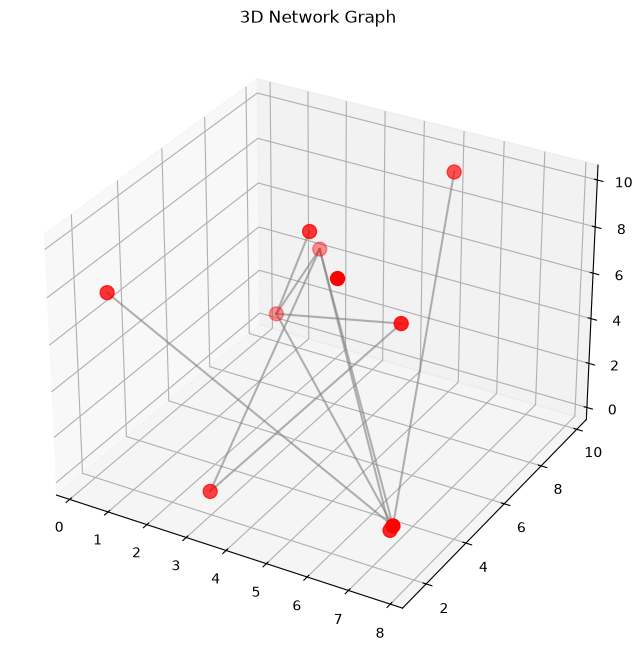

In [29]:
import networkx as nx

def create_3d_graph():
    G = nx.erdos_renyi_graph(10, 0.3) # random graph

    pos = {node: (np.random.uniform(0, 10), np.random.uniform(0, 10), # generate 3D positions
                  np.random.uniform(0, 10)) for node in G.nodes()}
    
    fig = plt.figure(figsize = (10, 8))
    ax = fig.add_subplot(111, projection='3d') # create a 3D plot

    # draw edges
    for edge in G.edges():
        x = [pos[edge[0]][0], pos[edge[1]][0]]
        y = [pos[edge[0]][1], pos[edge[1]][1]]
        z = [pos[edge[0]][2], pos[edge[1]][2]]
        ax.plot(x, y, z, color='gray', alpha=0.6)

    # draw nodes
    xs, ys, zs, = zip(*[pos[node] for node in G.nodes()])
    ax.scatter(xs, ys, zs, c='red', s=100)

    ax.set_title('3D Network Graph')

    plt.show()

create_3d_graph()

In [32]:
mesh = o3d.io.read_triangle_mesh('mesh_terrain.ply')
mesh.compute_vertex_normals()

o3d.visualization.draw_geometries([mesh])

In [33]:
size = 1

vertices = size / 2 * np.array([
    [-1, -1, -1],
    [1, -1, -1],
    [1, 1, -1],
    [-1, 1, -1],
    [-1, -1, 1],
    [1, -1, 1],
    [1, 1, 1],
    [-1, 1, 1]
])

triangles = np.array([
    [0, 1, 2], [0, 2, 3],
    [4, 5, 6], [4, 6, 7],
    [0, 4, 5], [0, 5, 1],
    [2, 6, 7], [2, 7, 3],
    [0, 4, 7], [0, 7, 3],
    [1, 5, 6], [1, 6, 2]
])

mesh = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(vertices),
                                 o3d.utility.Vector3iVector(triangles))
mesh.compute_vertex_normals()

o3d.visualization.draw_geometries([mesh], mesh_show_back_face=True)

In [34]:
def cloud_to_image(pcd_np, resolution):
    minx = np.min(pcd_np[:, 0])
    maxx = np.max(pcd_np[:, 0])
    miny = np.min(pcd_np[:, 1])
    maxy = np.max(pcd_np[:, 1])
    width = int((maxx - minx) / resolution) + 1
    height = int((maxy - miny) / resolution) + 1
    image = np.zeros((height, width, 3), dtype=np.uint8)
    for point in pcd_np:
        x, y, *_ = point
        r, g, b = point[-3:]
        pixel_x = int((x - minx) / resolution)
        pixel_y = int((maxy - y) / resolution)
        image[pixel_y, pixel_x] = [r, g, b]
    return image


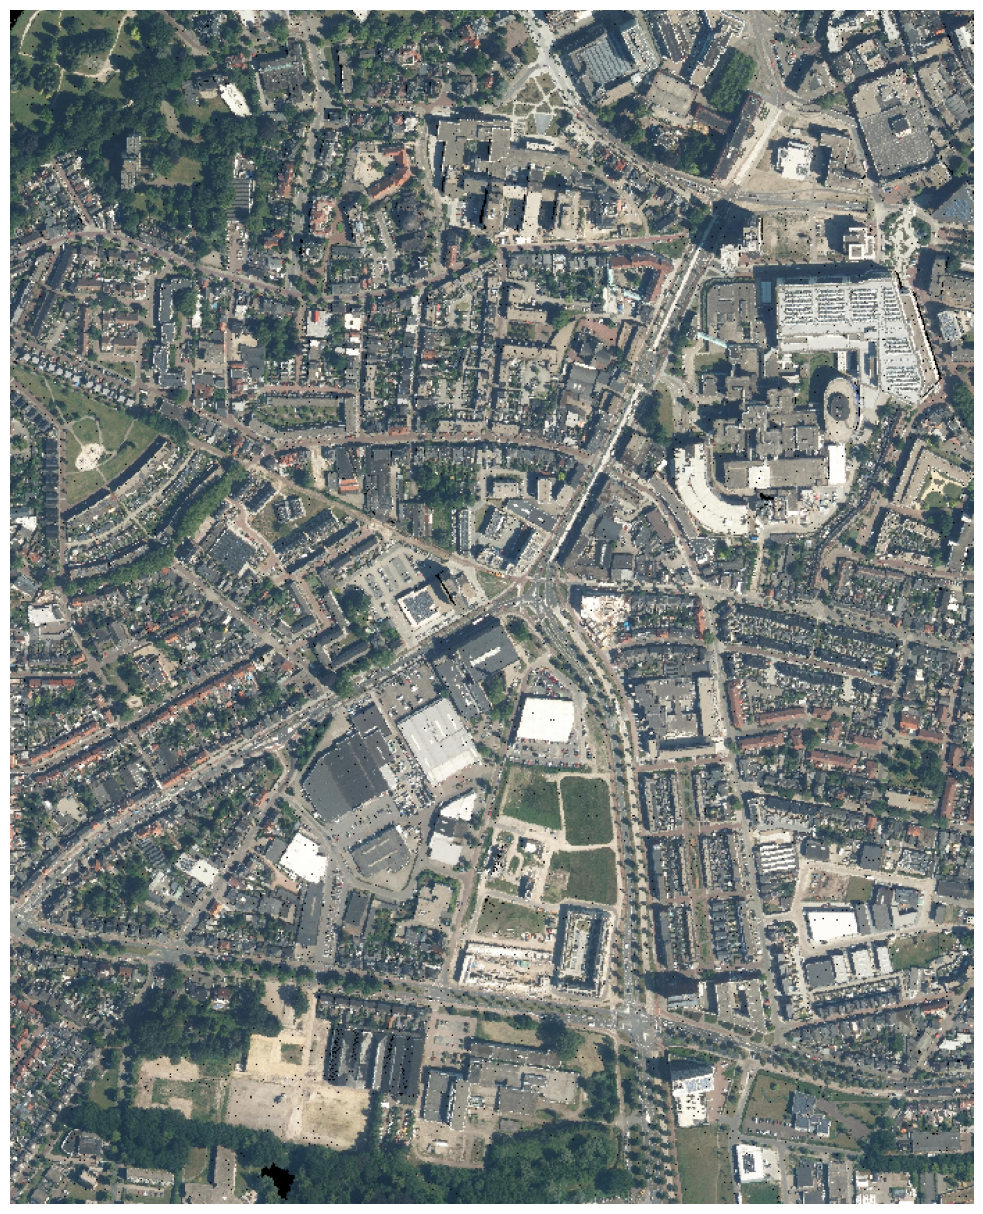

In [35]:
import laspy

# Reading the point cloud with laspy
pcd = laspy.read("34FN2_18.las")
# Transforming the point cloud to NumPy
pcd_np = np.vstack((pcd.x, pcd.y, pcd.z, (pcd.red/65535*255).astype(int),
(pcd.green/65535*255).astype(int), (pcd.blue/65535*255).astype(int))).transpose()
# Ortho projection
orthoimage = cloud_to_image(pcd_np, 1.5)
# Plotting and exporting
fig = plt.figure(figsize=(np.shape(orthoimage)[1]/72, np.shape(orthoimage)[0]/72))
fig.add_axes([0,0,1,1])
plt.imshow(orthoimage)
plt.axis('off')
plt.savefig("34FN2_18_orthoimage.jpg")

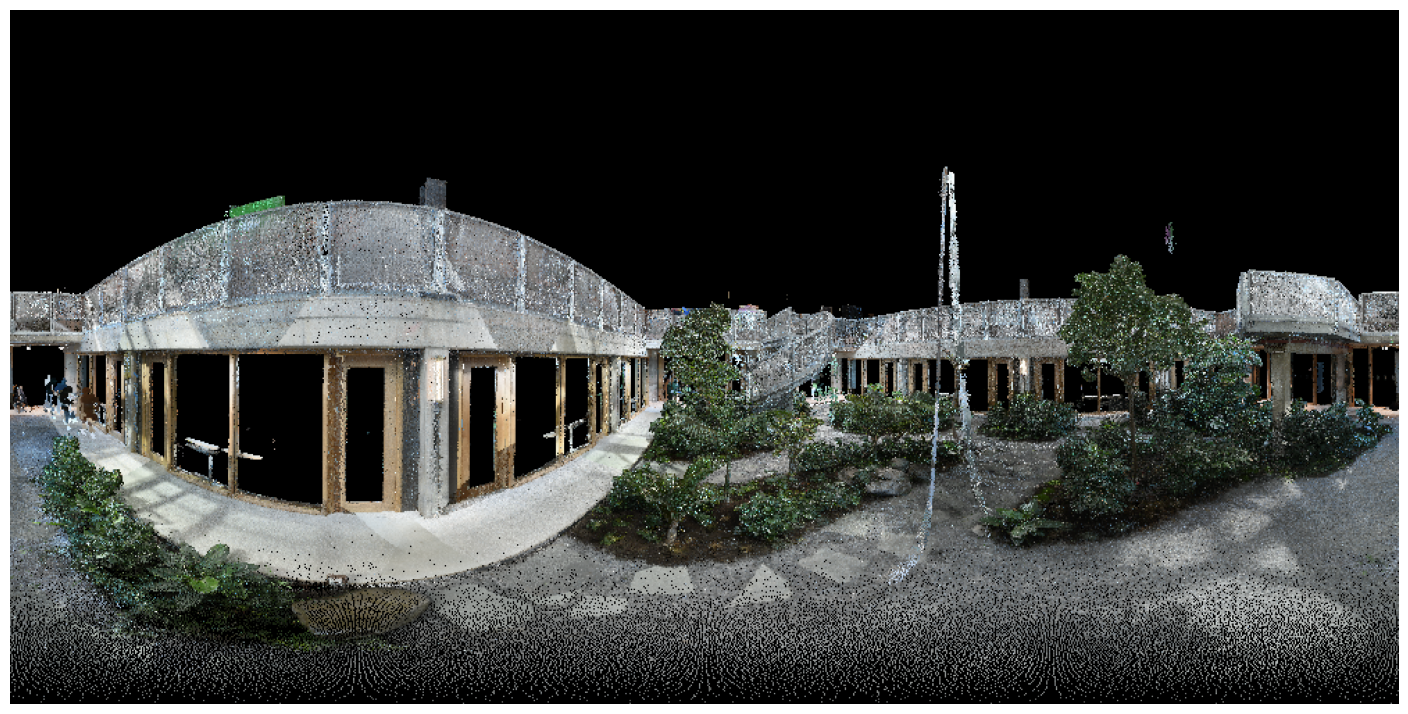

In [36]:
def generate_spherical_image(center_coordinates, point_cloud, colors, resolution_y=500):
    # Translate the point cloud by the negation of the center coordinates
    translated_points = point_cloud - center_coordinates
    # Convert 3D point cloud to spherical coordinates
    theta = np.arctan2(translated_points[:, 1], translated_points[:, 0])
    phi = np.arccos(translated_points[:, 2] / np.linalg.norm(translated_points, axis=1))
    # Map spherical coordinates to pixel coordinates
    x = (theta + np.pi) / (2 * np.pi) * (2 * resolution_y)
    y = phi / np.pi * resolution_y
    # Create the spherical image with RGB channels
    resolution_x = 2 * resolution_y
    image = np.zeros((resolution_y, resolution_x, 3), dtype=np.uint8)
    # Create the mapping between the point cloud and image coordinates
    mapping = np.full((resolution_y, resolution_x), -1, dtype=int)
    # Assign points to the image pixels
    for i in range(len(translated_points)):
        ix = np.clip(int(x[i]), 0, resolution_x - 1)
        iy = np.clip(int(y[i]), 0, resolution_y - 1)
        if mapping[iy, ix] == -1 or np.linalg.norm(translated_points[i]) < \
            np.linalg.norm(translated_points[mapping[iy, ix]]):
            mapping[iy, ix] = i
            image[iy, ix] = colors[i]
    return image, mapping

las = laspy.read('ITC_BUILDING.las')

coords = np.vstack((las.x, las.y, las.z))
point_cloud = coords.transpose()

r = (las.red/65535*255).astype(int)
g = (las.green/65535*255).astype(int)
b = (las.blue/65535*255).astype(int)
colors = np.vstack((r,g,b)).transpose()

resolution = 500

center_coordinates = [189, 60, 2]

spherical_image, mapping = generate_spherical_image(center_coordinates, point_cloud, colors, resolution)

fig = plt.figure(figsize=(np.shape(spherical_image)[1]/72,
                         np.shape(spherical_image)[0]/72))
fig.add_axes([0, 0, 1, 1])
plt.imshow(spherical_image)
plt.axis('off')

plt.savefig('ITC_BUILDING_spherical_projection.png')
plt.show()

In [37]:
point_cloud = o3d.io.read_point_cloud('structure_verviers.ply')

o3d.visualization.draw_geometries([point_cloud])

In [38]:
curr_max_depth = 8

octree = o3d.geometry.Octree(max_depth = curr_max_depth)
octree.convert_from_point_cloud(point_cloud)
o3d.visualization.draw_geometries([octree])

In [39]:
octree.locate_leaf_node(point_cloud.points[0])

(OctreePointColorLeafNode with color [0.572549, 0.545098, 0.419608] containing 77 points.,
 OctreeNodeInfo with origin [6.12408, -6.94074, 0.625316], size 0.0905313, depth 8, child_index 6)

In [40]:
import time

# In-Memory
def process_in_memory(dataset):
    start = time.time()
    # Load the entire dataset into memory
    entire_dataset = np.loadtxt(dataset, delimiter=';', skiprows=1)

    # Now you can perform computations on the entire dataset
    result = np.mean(entire_dataset, axis=0)
    end = time.time()
    print(f"In-Memory Time Elapsed: {end - start}")

    return result



# Out-of-Core
def process_out_of_core(dataset, chunk_size=1000):
    start = time.time()
    # Read the dataset in chunks
    reader = pd.read_csv(dataset, delimiter=';', chunksize=chunk_size)

    # Initialize an empty array to accumulate results
    result_accumulator = np.zeros((1, 6))
    counter=1

    for chunk in reader:
    # Perform computations on each chunk
        result_chunk = np.mean(chunk.to_numpy(), axis=0)

        # Accumulate results
        result_accumulator += result_chunk
        counter+=1
    end = time.time()
    print(f"Out-of-Core Time Elapsed: {end - start}")
    # return result_accumulator / len(reader)
    return result_accumulator/counter


In [41]:
process_in_memory('bike_florent.txt')

process_out_of_core('bike_florent.txt')

In-Memory Time Elapsed: 0.18329834938049316
Out-of-Core Time Elapsed: 0.832749605178833


array([[ 1.44960817,  1.24867481,  0.45720447, 99.75950647, 92.17670988,
        77.9702425 ]])